# 2.05. Многорукие бандиты

**План занятия**

1. Ограничения классического A/B-теста и дилемма exploration–exploitation.
2. Формальная постановка задачи и сожаление (regret).
3. Стратегии: ε-greedy, Softmax, UCB1, Bayesian UCB, Thompson Sampling.
4. Сравнение стратегий на симуляциях.
5. Бандит или A/B-тест: что мы выигрываем и что теряем.

### Библиотеки

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'

## Традиционное A/B-тестирование

На веб-сайтах сегодня постоянно происходит проверка разного рода гипотез. Какой должна быть кнопка "Купить": красной или синей? Какой заголовок привлекает больше всего кликов к этой новостной статье? На какую версию рекламы больше кликают?

Чтобы определить оптимальный ответ на эти вопросы, используют A/B-тесты - статистически обоснованный метод сравнения версий A и B.

По сути, в ходе тестирования аналитик пытается определить, совпадают ли значения некой величины в группах А и В, или различие в ней на самом деле случайность?

**A/B-тестирование** основано на классическом понимании статистической значимости. Когда мы придумываем новую функциональность продукта, мы хотим проверить, полезна ли она, прежде чем запускать ее для всей пользовательской базы.

В тесте обычно участвуют две группы: группа, получающая новую функциональность, (Treatment) и контрольная группа (Control). Затем мы измеряем ключевой показатель для обеих групп, например:

* среднее время пребывания на сайте (социальная сеть),
* среднее время оформления заказа (электронная коммерция)
* CTR или кол-во кликов (онлайн-реклама).

Разница между группами проверяется на статистическую значимость.
Классический статистический тест при правильном проведении (например z-тест, t-тест) гарантирует, что количество ложных срабатываний(FPR или ошибок первого рода) не превышает $\alpha$ (часто берут 5%). Это означает, что при отсутствии разницы между экспериментальной и контрольной группой тест будет показывать значимое отличие не более чем в 5% случаев.

Сбалансированный A/B-тест распределяет равное количество трафика на каждую группу в течение всего времени эксперимента. Мы при этом не можем регулировать распределение трафика во время теста в зависимости от того, что наблюдается. По сути, недостаток A / B-тестирования очевиден: если экспериментальная группа явно превосходит результаты контрольной, нам все равно придется потратить много трафика на контрольную группу, чтобы получить статистическую значимость.

## А можно ли по-другому?

**Exploration vs Exploitation**

Представьте, что вы стоите в зале казино перед рядом загадочных игровых автоматов. Каждый из них — «однорукий бандит» — готов выдать вам случайный выигрыш, но вы не знаете, какой из них щедр, а какой скуп. Ваша задача — максимизировать суммарный выигрыш за ограниченное число попыток. Но как это сделать, если вы даже не знаете, с какими вероятностями выплачивают эти автоматы?  

Эта аллегория лежит в основе задачи о многоруком бандите (Multi-Armed Bandit, MAB), одной из ключевых проблем в области адаптивного принятия решений. Название, разумеется, метафорично: «руки» (arms) — это альтернативные варианты действий (например, медицинские методы лечения, варианты рекламных объявлений или настройки алгоритма), каждый из которых приносит случайную, изначально неизвестную награду. Ваша цель — научиться распределять ограниченные ресурсы (будь то бюджет, время или пациенты) между этими вариантами так, чтобы в итоге получить как можно больше «выигрыша».  

Классическое A/B-тестирование, даже в его байесовской форме, подходит к этой задаче прямолинейно: сначала долго собирают данные, распределяя трафик равномерно между вариантами, и лишь потом, по итогам теста, выбирают победителя. Но что, если один из вариантов заведомо хуже? В таком подходе вы продолжаете вкладывать в него ресурсы до самого конца эксперимента, теряя потенциальную выгоду. MAB-алгоритмы решают эту проблему, отказываясь от жесткого разделения на фазу исследования и фазу эксплуатации. Вместо этого они учатся на лету, постепенно смещая фокус на более перспективные варианты, но при этом никогда полностью не отказываясь от исследования — вдруг текущий «лидер» на самом деле не оптимален, а вам просто повезло в первых нескольких попытках?  

Таким образом, задача MAB — это не просто оценка параметров (как в A/B-тестах), а *оптимизация процесса принятия решений в условиях неопределенности*. Алгоритмы многоруких бандитов должны балансировать между двумя противоречивыми целями: *исследовать* новые варианты, чтобы уточнить их потенциал, и *эксплуатировать* уже известные хорошие варианты, чтобы максимизировать немедленную отдачу - этот баланс известен как Exploration-Exploitation dilemma. Этот баланс делает MAB мощным инструментом в сценариях, где цена «слепого» тестирования высока, а эффект от выбора нужен прямо сейчас: онлайн-реклама, персонализированные рекомендации, короткие акции.  

## Формализация задачи MAB

Мы для определенности будем считать, что каждый игровой автомат - показ определенного типа рекламного баннера, а стоимость кликов в баннер одинаковая. При этих условиях выигрыш от выбора каждого баннера будет случайной величиной Бернуллиевского типа вида  $X_i \sim reward \times Bernoulli(p_i)$ , где  $reward$  - стоимость клика в баннер, а  $p_i$  - неизвестная нам вероятность клика в $i$-тый баннер. На оптимизационную задачу наш постоянный коэффициент  $reward$  не повлияет, поэтому будем считать, что выигрыш это 0 или 1.

Бернуллиевский многорукий бандит может быть описан как пара $(A,R)$, где

* У нас есть $K$ вариантов (баннеров/ручек) с неизвестными вероятностями "выигрыша" $(\theta_1,...,\theta_K)$
* В каждый момент времени $t$ мы "дергаем за одну из ручек" (например для каждого приходящего пользователя принимаем решение, какой баннер ему показать) и получаем "выигрыш" $r$ (он может быть равен 0).
* $A$ - множество действий, которые мы предприняли (каждое действие - взаимодействие с одной из ручек бандита), В результате каждого действия $a$ мы получаем "выигрыш" $Q(a)$, причем $Q(a) = E(r|a) = \theta$. Если в момент времени $t$ мы дёрнули за ручку $i$, то $Q(a_t) = \theta_i$
* $R$ - функция выигрыша. В нашем случае в каждый момент времени $t$ $r_t = R(a_t)$ равен 1, если человек кликнул в баннер, и это произойдет с вероятностью $Q(a_t) = \theta_i$, или равен 0, если человек в баннер не кликнул, и это произойдет с вероятностью $1 - \theta_i$


**Цель**

Наша задача состоит в том, чтобы максимизировать наш выигрыш за $T$ шагов, то есть:

$$\max \sum^T_{t=1} r_t$$

Чтобы это сделать, нам нужно попытаться идентифицировать ручку с максимальным выигрышем $\theta^*$:

$$\theta^* = Q(a^*) = max_{a \in A}(Q(a)) = max_{1\le i \le K}(\theta_i)$$

Потери из-за неверно выбранной ручки измеряют **накопленным сожалением (regret)**:

$$ L_T = \mathbb{E}\left[\sum^T_{t=1}(\theta^* - Q(a_t))\right]$$

Это разница между тем, что мы получили бы, всегда выбирая лучшую ручку, и тем, что получили на самом деле. У стратегии, которая навсегда продолжает исследовать с постоянной вероятностью, сожаление растёт линейно, а у хороших стратегий логарифмически.

## Основные стратегии

### ε-greedy

$\epsilon$-жадный алгоритм большую часть времени выбирает ручку, которая к настоящему моменту показала себя лучшей, но иногда выполняет случайное исследование новых ручек. Ценность каждого действия оценивается путем усреднения вознаграждений, связанных с целевым действием a, которые мы наблюдали до текущего временного шага t:

$$\hat Q_t(a) = \dfrac{1}{N_t(a)}\sum^t_{\tau = 1}r_\tau \mathbb{I}(a_\tau = a)$$

Здесь
* $\mathbb{I}$ - индикаторная функция, равная 1, если внутри истинное утверждение и 0, если ложное.
* $N_t(a)$ - количество раз, в которых было выбрано действие $a$.

С малой вероятностью $\epsilon$ мы выбираем случайную ручку, а с вероятностью $1 - \epsilon$ — лучшую на данный момент. Если $\epsilon$ постоянно, мы продолжаем тратить долю $\epsilon$ показов на случайные ручки всё время, поэтому сожаление растёт линейно.

### Softmax

В отличие от ε-жадного подхода, где исследование происходит *равномерно* по всем рукам, стратегия **Softmax** (также известная как *Болтцмановское распределение*) реализует *взвешенное* исследование. Идея заключается в том, что вероятность выбора руки растёт экспоненциально с её текущей оценкой: чем перспективнее рука выглядит, тем чаще её стоит проверять, но *никогда не исключая полностью* даже малоперспективные варианты. Это создает естественный баланс между эксплуатацией и целенаправленным исследованием.


1.  **Оценка ценности руки:** Как и в ε-жадном подходе, мы поддерживаем текущую оценку средней награды для каждой руки $a$:
$$
\hat{Q}_t(a) = \dfrac{1}{N_t(a)}\sum^{t}_{\tau=1} r_\tau \mathbb{I}(a_\tau = a)
$$
    Здесь:
   * $N_t(a)$ — количество выборов руки $a$ к моменту $t$
   * $\mathbb{I}$ — индикаторная функция.

2.  **Преобразование в вероятности:** Ключевое отличие Softmax — вычисление вероятности выбора руки $a$ на шаге $t$ по формуле **экспоненциального взвешивания**:
$$
    P_t(a) = \dfrac{\exp\left(\dfrac{\hat{Q}_t(a)}{\tau_t}\right)}{\sum_{b=1}^{K} \exp\left(\dfrac{\hat{Q}_t(b)}{\tau_t}\right)}
$$
    Здесь:
   * $\exp(\cdot)$ — экспоненциальная функция.
   * $\tau_t > 0$ — параметр **"температура"** (*temperature*), управляющий уровнем исследования.


Выбор температуры позволяет регулировать степень нашей заинтересованности в исследовании новых ручек:

*   **Высокая температура ($\tau_t \to \infty$):**  
    Экспоненты $\exp(\hat{Q}_t(a) / \tau_t)$ стремятся к 1 для всех рук. Знаменатель суммы становится равным $K \times 1 = K$. Вероятности выбора всех рук становятся **равномерными**: $P_t(a) = 1/K$. Алгоритм активно исследует все варианты.

*   **Низкая температура ($\tau_t \to 0^+$):**  
    Экспонента для руки с *максимальной* оценкой $\hat{Q}_t(a)$ будет значительно больше, чем для других. Её вероятность $P_t(a^*)$ стремится к 1, а вероятности остальных рук — к 0. Алгоритм **эксплуатирует** текущего лидера.

*   **Умеренная температура ($\tau_t > 0$):**  
    Руки с *более высокими* оценками $\hat{Q}_t(a)$ получают *более высокие* вероятности выбора. Руки с *низкими* оценками получают *ненулевые, но малые* вероятности. Это и есть **взвешенное исследование**: алгоритм чаще проверяет руки, которые выглядят перспективнее, но сохраняет шанс (пусть и небольшой) для проверки аутсайдеров — вдруг их начальные оценки были неудачной случайностью?


Температура задаётся в тех же единицах, что и награда: при вероятностях около 0.1 разница оценок мала, и $\tau = 1$ почти не отличается от случайного выбора. На практике $\tau_t$ часто **уменьшается** со временем (например, $\tau_t = 1 / \ln(t+1)$ или $\tau_t = c / \sqrt{t}$). Это реализует естественную эволюцию стратегии:
1.  **Вначале ($t$ мало, $\tau_t$ высоко):** Активное исследование всех рук для первичной оценки.
2.  **Со временем ($t$ растет, $\tau_t$ падает):** Фокус постепенно смещается в сторону рук с лучшими историческими показателями. Вероятности выбора субоптимальных рук плавно уменьшаются, но не исчезают полностью.

### Upper Confidence Bounds (UCB)

Случайное исследование в предыдущих стратегиях позволяет опробовать варианты, о которых мы мало знаем. Но оно не отличает ручку, про которую уже всё ясно, от ручки, которую мы почти не пробовали: можно снова и снова исследовать вариант с заведомо низкой долей кликов. Можно уменьшать параметр исследования со временем, а можно оцифровать, насколько достоверна наша оценка. Будем чаще дёргать ручки с высокой неопределённостью и реже те, в оценке которых уверены. Другими словами, мы предпочитаем ручки, у которых высок потенциал для оптимального выигрыша.

Алгоритм **Upper Confidence Bounds (UCB)** измеряет такой потенциал с помощью оценки сверху доверительной границы значения вознаграждения, которое мы можем с этой ручки получить. Обозначим эту оценку за $\hat U_t(a)$. Раз у нас оценка сверху, то истинное значение с большой вероятностью должно находиться ниже нашего измеренного значения + наша оценка доверительной границы:

$$Q(a)\le \hat Q_t(a) + \hat U_t(a)$$

При этом оценка $\hat U_t(a)$ зависит от $N_t(a)$: чем больше попыток, тем меньше $\hat U_t(a)$.

В алгоритме UCB мы всегда выбираем такое действие, которое максимизирует нашу оценку:

$$a^{UCB}_t = argmax_{a \in A} \hat Q_t(a) + \hat U_t(a)$$

Остается понять, как нам, собственно, оценить $\hat U_t(a)$

Чтобы оценить нашу границу, не привязываясь к явному виду распределения, воспользуемся [неравенством Хёффдинга](http://cs229.stanford.edu/extra-notes/hoeffding.pdf). Это общее утверждение, которое справедливо для всех ограниченных распределений (мы сформулируем его для интервала $[0,1]$):

Пусть $X_1 ... X_t$ - независимые, одинаково распределенные случайные величины, каждая из которых находится в интервале $[0,1]$, тогда для любого $u > 0$ справедливо неравенство:

$$P(E[X] > \bar{X_t}+u) \le e^{-2tu^2} \text{ , где } \bar{X_t} = \dfrac{1}{t}\sum^t_{\tau = 1}X_{\tau}$$

Теперь переведем это утверждение на язык наших ручек и выигрышей. У нас:

* награды ручки $a$ — случайные величины из формулировки теоремы;
* $N_t(a)$ играет роль размера выборки $t$ из теоремы;
* $Q(a)$ - истинное значение среднего (вероятность выигрыша)
* $\hat Q_t(a)$ - выборочная оценка среднего на шаге $t$(вероятность выигрыша, оцененная по выборке)
* $u = \hat U_t(a)$ - наша оценка $UCB$

Значит для нашего бандитского эксперимента оценка примет вид:

$$P(Q(a) > \hat Q_t(a) + \hat U_t(a)) \le e^{-2N_t(a)\hat U_t(a)^2}$$

Мы хотим выбрать границу так, чтобы с большой вероятностью истинное среднее оказывалось меньше, чем сумма выборочной оценки и оценки $UCB$. Таким образом, вероятность $e^{-2N_t(a)\hat U_t(a)^2}$ должна быть маленькой величиной. Допустим, это какая-то маленькая вероятность $p$, тогда:

$$e^{-2N_t(a)\hat U_t(a)^2} = p \text{ или, иначе говоря:}$$

$$U_t(a) = \sqrt{\dfrac{-\log p}{2N_t(a)}}$$


Вероятность ошибки разумно уменьшать со временем. Если $p = t^{-4}$, тогда мы получим:

$$U_t(a) = \sqrt{\dfrac{2logt}{N_t(a)}}$$

$$a^{UCB1}_t = argmax_{a \in A} \hat Q_t(a) + \sqrt{\dfrac{2logt}{N_t(a)}}$$

Такая оценка называется  **UCB1**

Но в таком выводе мы не делаем никаких предположений о распределении вознаграждения, и поэтому приходится полагаться на общую оценку через неравенство Хёффдинга. Если мы сможем заранее узнать распределение, границы можно будет оценить лучше.

Выигрыши у нас бернуллиевские, поэтому априорное и апостериорное распределения вероятности выигрыша можно выбрать бета-распределением: параметры обновляются счётчиками успехов и неудач. Если постериор близок к нормальному, верхнюю границу можно задать как среднее постериора плюс две или три его стандартные ошибки (правило двух или трёх сигм). Про обновление параметров бета-распределения хорошо почитать в [этой](https://arxiv.org/pdf/1709.03162.pdf) статье.

Такое решение будем называть **байесовской UCB**. Это упрощённый вариант: в исходном Bayes-UCB граница задаётся квантилем постериора, а не числом сигм.
$$a^{Bayes\ UCB}_t = \arg\max_{a \in A} \hat Q_t(a) + c \cdot \sigma(\text{Beta}_a), \quad c = 2 \text{ или } 3$$

### Thompson Sampling

На каждом временном шаге в этом методе мы хотим выбирать действие a в соответствии с вероятностью того, что оно является оптимальным. Оценивается это так:

$$\pi(a|h_t) = P[Q(a) > Q(a'), \forall a' \not = a|h_t] = E_{R|h_t}[1(a= argmax_{a \in A}Q(a))]$$

Здесь $\pi(a|h_t)$ - вероятность принятия решения $a$ при условии истории $h_t$ - набора предыдущих действий.

Для Бернуллиевского бандита логичным(как и в предыдущем случае) кажется моделировать $Q(a)$ с помощью бета-распределения, так как $Q(a)$ есть неизвестное $\theta$ для распределения Бернулли. Значение $Beta(\alpha,\beta)$ находится в интервале $[0,1]$, $\alpha$ и $\beta$ отвечают числу успехов и неудач.

Инициализируем параметры $\alpha$ и $\beta$ нашего бета-распределения на основе некоторых априорных знаний или убеждений для каждой ручки, например:

* При $\alpha = 1$ и $\beta = 1$ распределение равномерно: мы ничего не знаем о вероятности выигрыша.
* При $\alpha = 1000$ и $\beta = 9000$ мы крайне уверены, что вероятность выигрыша составляет 10%

В каждый момент времени $t$ мы сэмплируем ожидаемый выигрыш $\hat Q_t(a)$ из текущего бета-распределения $\text{Beta}(\alpha_i,\beta_i)$ для каждого действия. Лучшее действие выбирается среди вариантов $a^{TS}_t = argmax_{a \in A}\hat Q(a)$. Затем мы получаем истинное значение выигрыша, и можем соответствующим образом обновить бета-распределение, которое по сути делает байесовский вывод для вычисления апостериорного значения с известным априорным значением и правдоподобием получения выборочных данных.

$\alpha_i \leftarrow \alpha_i + r_t \mathbb{I}(a^{TS}_t==a)$

$\beta_i \leftarrow \beta_i + (1-r_t)\mathbb{I}(a^{TS}_t==a)$

Оценки $\hat Q(a)$ сэмплируются из постериоров, поэтому каждая ручка выбирается ровно с той вероятностью, с какой она является оптимальной при наблюдаемой истории.

Анимация показывает три ручки: постериоры сужаются, а показы постепенно уходят в лучшую ручку.

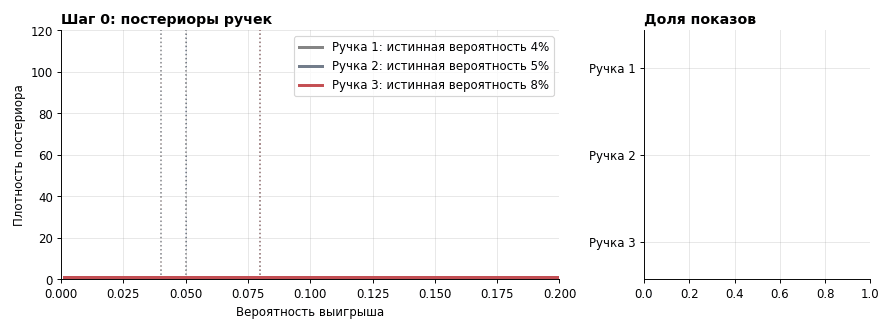

## Реализация

Запрограммируем стратегии так, чтобы запускать их сразу на многих независимых прогонах: один прогон бандита очень шумный, и выводы по нему ненадёжны. Каждая стратегия получает матрицы числа показов и выигрышей (прогоны × ручки) и возвращает выбранную ручку для каждого прогона.

In [2]:
def empirical_means(pulls: np.ndarray, wins: np.ndarray) -> np.ndarray:
    """Считает средний выигрыш ручек, у непоказанных ручек оценка равна 1."""
    return np.where(pulls > 0, wins / np.maximum(pulls, 1), 1.0)


def random_tiebreak(scores: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Выбирает лучшую ручку в каждом прогоне, случайно разбивая ничьи."""
    return np.argmax(scores + 1e-9 * rng.random(scores.shape), axis=1)


class EpsilonGreedy:
    """С вероятностью eps выбирает случайную ручку, иначе лучшую."""

    def __init__(self, eps: float = 0.01):
        self.eps = eps

    def select(self, pulls, wins, t, rng):
        arms = random_tiebreak(empirical_means(pulls, wins), rng)
        explore = rng.random(len(arms)) < self.eps
        arms[explore] = rng.integers(0, pulls.shape[1], explore.sum())
        return arms


class Softmax:
    """Выбирает ручку с вероятностью, экспоненциальной от оценки."""

    def __init__(self, tau: float = 0.05):
        self.tau = tau

    def select(self, pulls, wins, t, rng):
        logits = empirical_means(pulls, wins) / self.tau
        probabilities = np.exp(logits - logits.max(axis=1, keepdims=True))
        probabilities /= probabilities.sum(axis=1, keepdims=True)
        return (probabilities.cumsum(axis=1) < rng.random((len(pulls), 1))).sum(axis=1)


class UCB1:
    """Выбирает ручку с максимальной верхней границей Хёффдинга."""

    def select(self, pulls, wins, t, rng):
        bonus = np.sqrt(2 * np.log(max(t, 1)) / np.maximum(pulls, 1))
        scores = np.where(pulls > 0, wins / np.maximum(pulls, 1) + bonus, np.inf)
        return random_tiebreak(np.nan_to_num(scores, posinf=1e6), rng)


class BayesianUCB:
    """Выбирает ручку с максимальной границей: среднее постериора плюс c стандартных отклонений."""

    def __init__(self, c: float = 3):
        self.c = c

    def select(self, pulls, wins, t, rng):
        alpha, beta = 1 + wins, 1 + pulls - wins
        total = alpha + beta
        std = np.sqrt(alpha * beta / (total ** 2 * (total + 1)))
        return random_tiebreak(alpha / total + self.c * std, rng)


class ThompsonSampling:
    """Выбирает ручку с максимальным значением, выбранным из постериора."""

    def select(self, pulls, wins, t, rng):
        return np.argmax(rng.beta(1 + wins, 1 + pulls - wins), axis=1)


def run_bandit(policy, probabilities: np.ndarray, horizon: int, n_runs: int = 300, seed: int = 42) -> dict:
    """Запускает стратегию на независимых прогонах и возвращает средние кривые."""
    rng = np.random.default_rng(seed)
    probabilities = np.asarray(probabilities, dtype=float)
    pulls = np.zeros((n_runs, len(probabilities)))
    wins = np.zeros_like(pulls)
    gaps = probabilities.max() - probabilities
    regret = np.zeros(horizon)
    optimal = np.zeros(horizon)
    best = probabilities.argmax()
    rows = np.arange(n_runs)

    for t in range(horizon):
        arms = policy.select(pulls, wins, t + 1, rng)
        pulls[rows, arms] += 1
        wins[rows, arms] += rng.random(n_runs) < probabilities[arms]
        regret[t] = gaps[arms].mean()
        optimal[t] = (arms == best).mean()
    return {'regret': regret.cumsum(), 'optimal': optimal, 'pulls': pulls, 'wins': wins}


POLICIES = {
    'ε-greedy, ε = 0.1': (EpsilonGreedy(0.1), GRAY),
    'ε-greedy, ε = 0.01': (EpsilonGreedy(0.01), ORANGE),
    'Softmax, τ = 0.05': (Softmax(0.05), PURPLE),
    'UCB1': (UCB1(), RED),
    'Bayesian UCB, c = 3': (BayesianUCB(3), GREEN),
    'Thompson Sampling': (ThompsonSampling(), BLUE),
}


def compare_policies(probabilities: list, horizon: int, title: str) -> pd.DataFrame:
    """Рисует сожаление и долю выбора лучшей ручки и возвращает итоговую таблицу."""
    results = {name: run_bandit(policy, probabilities, horizon) for name, (policy, _) in POLICIES.items()}
    window = max(horizon // 50, 1)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for name, result in results.items():
        color = POLICIES[name][1]
        axes[0].plot(np.arange(1, horizon + 1), result['regret'], color=color, linewidth=2, label=name)
        smoothed = np.convolve(result['optimal'], np.ones(window) / window, mode='valid')
        axes[1].plot(np.arange(window, horizon + 1), smoothed, color=color, linewidth=2)
    axes[0].set(xlabel='Шаг', ylabel='Накопленное сожаление', title=title)
    axes[0].legend(fontsize=10)
    axes[1].set(xlabel='Шаг', ylabel='Доля выбора лучшей ручки', ylim=(0, 1.02), title='Как быстро стратегии находят лучшую ручку')
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({name: {'Сожаление': result['regret'][-1], 'Лучшая ручка в конце': result['optimal'][-horizon // 10:].mean()}
                         for name, result in results.items()}).T.round(3)

#### Эксперимент: сильно различающиеся ручки

Начнём с 10 ручек с вероятностями от 1% до 95%.

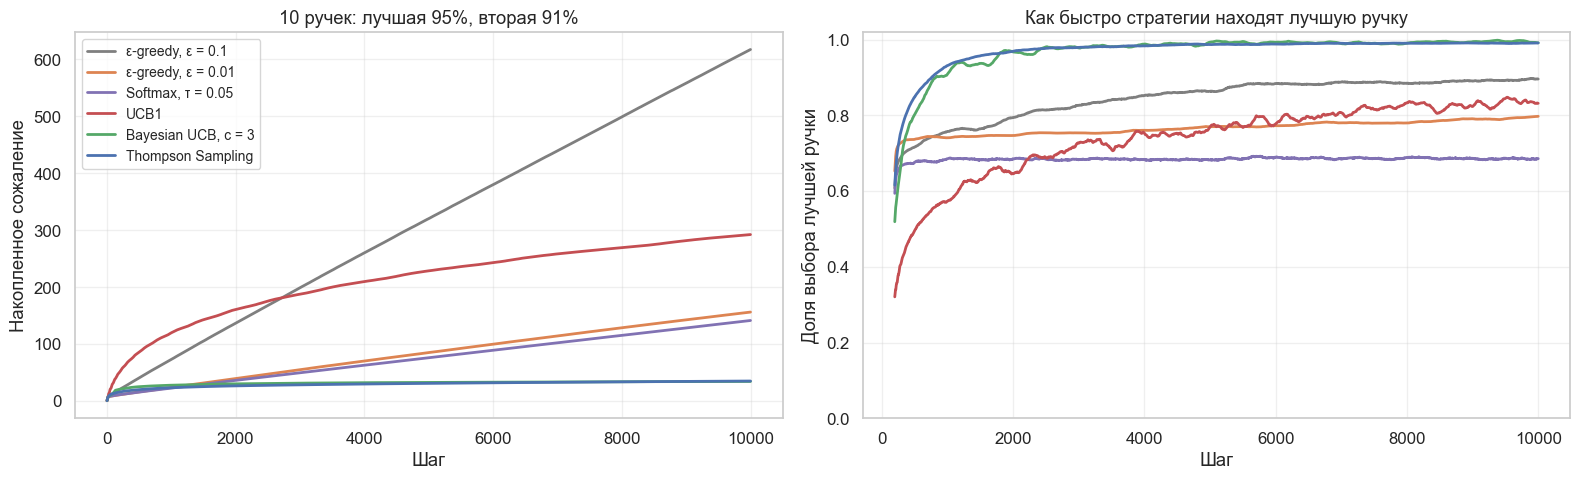

,Сожаление,Лучшая ручка в конце
"ε-greedy, ε = 0.1",617.146,0.893
"ε-greedy, ε = 0.01",156.154,0.793
"Softmax, τ = 0.05",141.385,0.685
UCB1,292.239,0.834
"Bayesian UCB, c = 3",34.384,0.995
Thompson Sampling,35.112,0.990


In [3]:
compare_policies([0.63, 0.2, 0.02, 0.18, 0.05, 0.91, 0.61, 0.01, 0.09, 0.95], 10_000, '10 ручек: лучшая 95%, вторая 91%')

Bayesian UCB и Thompson Sampling почти не ошибаются: сожаление около 35 и выбор лучшей ручки в 99% случаев. UCB1 здесь заметно хуже (292): его граница Хёффдинга рассчитана на любое распределение на $[0, 1]$ и слишком широка. У ε-greedy с $\varepsilon = 0.1$ сожаление большое (617), потому что 10% показов всегда тратятся на случайные ручки. С $\varepsilon = 0.01$ оно ниже (156), но к концу лучшая ручка выбирается только в 79% случаев: стратегия иногда застревает на ручке с вероятностью 91%. Softmax с $\tau = 0.05$ плохо отличает 95% от 91%.

#### Эксперимент: близкие ручки

В продуктовых задачах конверсии обычно низкие, а различия маленькие. Здесь же видно, как зависит результат от настроек.

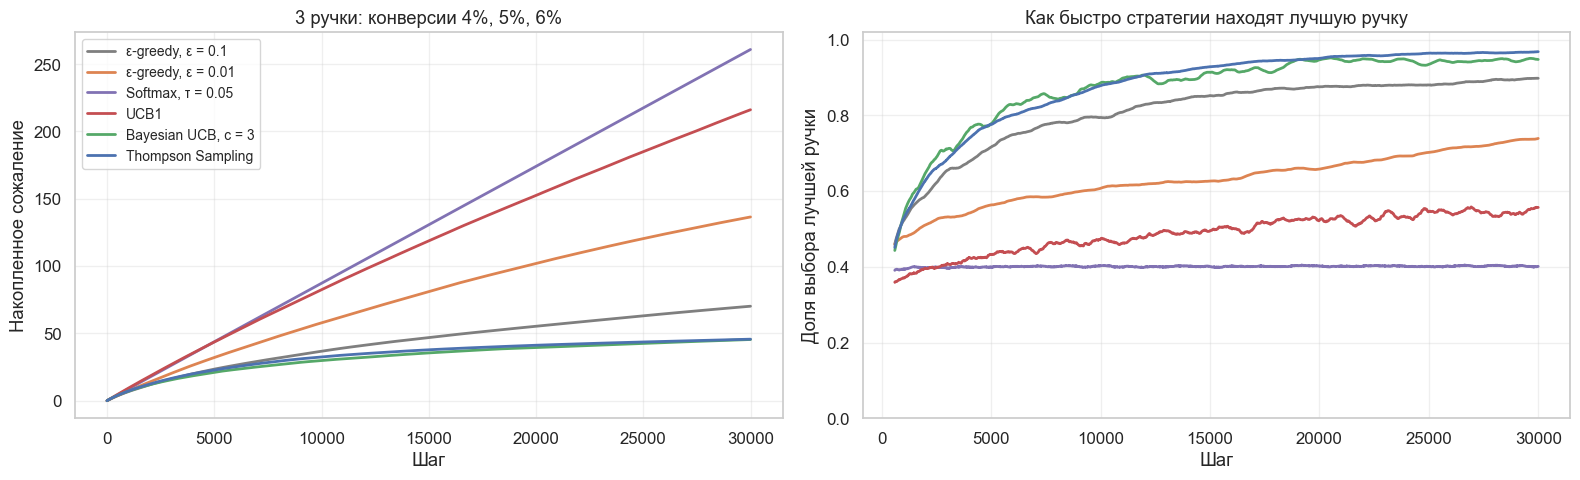

,Сожаление,Лучшая ручка в конце
"ε-greedy, ε = 0.1",70.189,0.895
"ε-greedy, ε = 0.01",136.492,0.731
"Softmax, τ = 0.05",260.894,0.402
UCB1,216.138,0.544
"Bayesian UCB, c = 3",45.456,0.946
Thompson Sampling,45.700,0.966


In [4]:
compare_policies([0.04, 0.05, 0.06], 30_000, '3 ручки: конверсии 4%, 5%, 6%')

Картина меняется. Thompson Sampling и Bayesian UCB снова лучшие (сожаление около 46). Но теперь ε-greedy с $\varepsilon = 0.1$ лучше, чем с $\varepsilon = 0.01$ (70 против 136): на близких ручках маленькое $\varepsilon$ застревает на неудачном лидере. Softmax с той же $\tau = 0.05$ становится почти случайным (сожаление 261, лучшая ручка в 40% случаев), потому что при конверсиях около 5% разности оценок намного меньше температуры. UCB1 тоже страдает: 216. Настраиваемые стратегии требуют подбора под масштаб наград, а Thompson Sampling работает без настройки.

**Попробуйте сами.** Эта ячейка интерактивная: задайте разницу между ручками и параметры стратегий. Статичные версии показаны выше.

In [5]:
def bandit_demo(base_percent: float = 5.0, gap_percent: float = 1.0, eps: float = 0.01, tau: float = 0.05) -> None:
    """Сравнивает стратегии на двух ручках с заданной разницей."""
    probabilities = [base_percent / 100, (base_percent + gap_percent) / 100]
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for name, policy, color in [('ε-greedy', EpsilonGreedy(eps), ORANGE), ('Softmax', Softmax(tau), PURPLE), ('UCB1', UCB1(), RED), ('Thompson Sampling', ThompsonSampling(), BLUE)]:
        ax.plot(run_bandit(policy, probabilities, 5000, n_runs=100)['regret'], color=color, linewidth=2, label=name)
    ax.set(xlabel='Шаг', ylabel='Накопленное сожаление', title=f'Конверсии {probabilities[0]:.1%} и {probabilities[1]:.1%}')
    ax.legend()
    plt.tight_layout()
    plt.show()


interact(bandit_demo,
         base_percent=FloatSlider(value=5, min=1, max=50, step=1, description='База, %'),
         gap_percent=FloatSlider(value=1, min=0.2, max=10, step=0.2, description='Разница, %'),
         eps=FloatSlider(value=0.01, min=0, max=0.3, step=0.01, description='ε'),
         tau=FloatSlider(value=0.05, min=0.005, max=0.5, step=0.005, description='τ', readout_format='.3f'));

## Бандит или A/B-тест?

Бандит и A/B-тест решают разные задачи. Бандит минимизирует потери **во время** эксперимента, а A/B-тест даёт корректный вывод об эффекте **после** него. Сравним их на двух ручках с конверсиями 5% и 6%.

A/B-тест здесь — стратегия **explore-then-commit**: сначала делим трафик поровну на рассчитанный размер выборки, затем весь трафик отдаём победителю. Такой дизайн похож на бандита, но фаза исследования фиксирована.

In [6]:
def ab_then_commit(probabilities: list, n_per_arm: int, horizon: int, n_runs: int = 3000, seed: int = 1) -> dict:
    """Считает сожаление стратегии: равное деление на n_per_arm, затем запуск значимого победителя."""
    rng = np.random.default_rng(seed)
    p = np.asarray(probabilities)
    a = rng.binomial(n_per_arm, p[0], n_runs) / n_per_arm
    b = rng.binomial(n_per_arm, p[1], n_runs) / n_per_arm
    pooled = (a + b) / 2
    z = (b - a) / np.sqrt(2 * pooled * (1 - pooled) / n_per_arm)
    picks_best = z > stats.norm.ppf(0.975)
    gap = p.max() - p.min()
    test_regret = n_per_arm * gap
    after_regret = (horizon - 2 * n_per_arm) * gap * (~picks_best).mean()
    return {'Сожаление': test_regret + after_regret, 'Сожаление в тесте': test_regret, 'Лучший вариант запущен': picks_best.mean()}


p_arms = [0.05, 0.06]
z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
n_ab = int(np.ceil(2 * z_sum ** 2 * np.mean(p_arms) * (1 - np.mean(p_arms)) / 0.01 ** 2))

rows = {}
horizons = [2 * n_ab, 5 * n_ab, 20 * n_ab]
for horizon in horizons:
    ts = run_bandit(ThompsonSampling(), p_arms, horizon, n_runs=200)
    ab = ab_then_commit(p_arms, n_ab, horizon)
    rows[horizon] = {'A/B, затем запуск': ab['Сожаление'], 'Thompson Sampling': ts['regret'][-1],
                     'Лучшая ручка в конце у TS': ts['optimal'][-max(horizon // 20, 1):].mean(), 'A/B запустил лучший': ab['Лучший вариант запущен']}

print(f'Размер группы A/B-теста: {n_ab}')
pd.DataFrame(rows).T.rename_axis('Всего пользователей').round(3)

Размер группы A/B-теста: 8159


,"A/B, затем запуск",Thompson Sampling,Лучшая ручка в конце у TS,A/B запустил лучший
Всего пользователей,,,,
16318,81.590,25.335,0.939,0.798
40795,131.115,33.479,0.980,0.798
163180,378.741,43.366,0.996,0.798


Thompson Sampling выигрывает по сожалению при любом горизонте: 25 против 82 при 16 тысячах пользователей и 43 против 379 при 163 тысячах. Причины две. Во-первых, A/B-тест всё время отдаёт половину трафика худшему варианту. Во-вторых, A/B здесь останавливается на правиле значимости: при мощности 80% лучший вариант запускается только в 80% случаев, а в остальных мы остаёмся на контроле. Это консервативное правило, и в сравнении оно играет не в пользу A/B.

Но A/B-тест отвечает на другой вопрос: он даёт корректную оценку эффекта и контроль ошибки, которые дальше нужны для долгосрочного решения.

**Что мы теряем: выводы на адаптивных данных**

Данные бандита собраны адаптивно: ручка получает новые показы, когда её оценка высока, и теряет их, когда оценка случайно упала. Поэтому среднее по ручке смещено, а обычный тест на таких данных не контролирует ошибку. Проверим на A/A: две ручки с одинаковой конверсией 5%, Thompson Sampling на 20 000 показов.

In [7]:
def adaptive_inference(policy, horizon: int = 20_000, p: float = 0.05, n_runs: int = 5000, seed: int = 11) -> dict:
    """Проверяет смещение оценок и ошибку z-теста на данных стратегии при равных ручках."""
    result = run_bandit(policy, [p, p], horizon, n_runs=n_runs, seed=seed)
    pulls, wins = result['pulls'], result['wins']
    means = wins / np.maximum(pulls, 1)
    pooled = wins.sum(axis=1) / pulls.sum(axis=1)
    se = np.sqrt(pooled * (1 - pooled) * (1 / np.maximum(pulls, 1)).sum(axis=1))
    z = (means[:, 1] - means[:, 0]) / se
    leader = pulls.argmax(axis=1)
    rows = np.arange(n_runs)
    return {'Среднее у лидера': means[rows, leader].mean(), 'Среднее у отстающей': means[rows, 1 - leader].mean(),
            'Доля показов отстающей': (pulls.min(axis=1) / pulls.sum(axis=1)).mean(), 'Ошибка z-теста': (np.abs(z) > 1.96).mean()}


class EqualSplit:
    """Равное случайное деление, как в A/B-тесте."""

    def select(self, pulls, wins, t, rng):
        return rng.integers(0, pulls.shape[1], len(pulls))


pd.DataFrame({'A/B: равное деление': adaptive_inference(EqualSplit()), 'Thompson Sampling': adaptive_inference(ThompsonSampling())}).T.round(4)

,Среднее у лидера,Среднее у отстающей,Доля показов отстающей,Ошибка z-теста
A/B: равное деление,0.0499,0.0499,0.4972,0.0512
Thompson Sampling,0.0506,0.0458,0.2601,0.1122


Различий между ручками нет, но у Thompson Sampling отстающая ручка выглядит хуже реальности: 4.58% вместо 5%, а лидер завышен до 5.06%. При равном делении смещения нет. Причина в том, что неудачное начало лишает ручку показов и шансов исправить оценку. Обычный z-тест на данных бандита даёт 11.2% ложных срабатываний вместо 5%. Поэтому для выводов по данным бандита нужны специальные методы, а обычный тест применять нельзя.

**Когда что использовать**

| Ситуация | Что подходит |
| :--- | :--- |
| Нужно принять долгосрочное решение и оценить эффект | A/B-тест |
| Нужны метрики, которые долго накапливаются, и анализ по срезам | A/B-тест |
| Короткий горизонт: акция, новостной заголовок, сезонный баннер | Бандит |
| Много вариантов, цена плохого варианта высока | Бандит |
| Постоянный подбор, где нет единого решения | Бандит |
| Отклик приходит с большой задержкой | С бандитом осторожно: оценки устаревают |
| Метрика меняется во времени (день недели, сезон) | С бандитом осторожно: распределение трафика смешивается с сезонностью |

## Заключение

* Задача бандита — минимизировать потери во время обучения, а цель A/B-теста — корректный вывод об эффекте.
* ε-greedy прост, но при постоянном ε сожаление растёт линейно. Softmax чувствителен к масштабу наград.
* UCB исследует неопределённость, а его граница следует из неравенства Хёффдинга.
* Thompson Sampling выбирает ручку с вероятностью того, что она лучшая, и хорошо работает без настройки.
* По сожалению Thompson Sampling выигрывает у A/B-теста, но A/B-тест даёт корректную оценку эффекта, нужную для долгосрочных решений.
* Обычные тесты на данных бандита некорректны: оценки смещены, а ошибка первого рода завышена.